# Первоначальная обработка данных

Проект «Подбор домов Красноярска по анкете». Одна запись — оценка адреса по анкете. Целевой ответ — «Добавили бы вы этот дом в список для просмотра?».

Каталог содержит реальные адреса и расстояния по прямой. Анкеты и ответы сгенерированы для учебного исследования. Запускайте все ячейки. CSV берутся из папки **data** рядом с ноутбуком.

[Данные каталога © OpenStreetMap contributors, ODbL](https://www.openstreetmap.org/copyright).

## Загрузка и проверка

Каталог собран из листа «Данные» книги **Krasnoyarsk_baza_zhilykh_domov_orig (1).xlsx**. Согласно листу «Методика», снимок сформирован 18.11.2026 из OpenStreetMap. Генератор **prepare_data.py** воспроизводит три CSV с seed=42.

In [19]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.model_selection import train_test_split

project = Path.cwd()
if (project / 'house_matching' / 'prepare_data.py').is_file():
    project = project / 'house_matching'
sys.path.insert(0, str(project))

from prepare_data import (
    DISTANCES, FEATURES, HOUSES_PER_SURVEY, LIMITS, PARKING, PLACES,
    PRIORITIES, SEED, SURVEY_COUNT, TARGET,
)

plt.rcParams.update({'font.family': 'DejaVu Sans', 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11})
blue, teal, terracotta, ink, grid = '#2964A3', '#087E77', '#B85B34', '#162B41', '#DCE6EF'
places = [russian for _, russian in PLACES.values()]
short = dict(zip(DISTANCES + LIMITS + PRIORITIES,
                 [f'{name} дома' for name in places] + [f'{name} в анкете' for name in places]
                 + [f'{name}: важность' for name in places + ['Парковка']]))
short['parking'] = 'Парковка'

houses = pd.read_csv(project / 'data' / 'houses.csv', dtype={'floors': 'Int64'})
surveys = pd.read_csv(project / 'data' / 'surveys.csv')
answers = pd.read_csv(project / 'data' / 'answers.csv')
pairs = answers.merge(houses, on='house_id', validate='many_to_one')
pairs = pairs.merge(surveys, on='survey_id', validate='many_to_one')

assert len(FEATURES) == 23 and len(surveys) == SURVEY_COUNT
assert len(pairs) == SURVEY_COUNT * HOUSES_PER_SURVEY
assert not pairs.duplicated(['survey_id', 'house_id']).any()
assert pairs.groupby('survey_id').size().eq(HOUSES_PER_SURVEY).all()
assert pairs[TARGET].isin([0, 1]).all()
fits_district = [district in district_list.split('|')
                 for district, district_list in zip(pairs['district'], pairs['districts'])]
assert all(fits_district)

train_ids, test_ids = train_test_split(surveys['survey_id'], test_size=.2, random_state=SEED)
assert set(train_ids).isdisjoint(test_ids)
eda = pairs.loc[pairs['survey_id'].isin(train_ids)].copy()
print(f'{len(houses):,} адресов · {len(surveys)} анкет · {len(pairs):,} ответов'.replace(',', ' '))
print(f'Для анализа отклика {len(train_ids)} анкет, для финального теста {len(test_ids)}.')
eda[FEATURES + [TARGET]].info()
display(eda[['survey_id', 'address', 'stop_m', 'want_stop_m', 'priority_stop', TARGET]].head())

22 065 адресов · 600 анкет · 18 000 ответов
Для анализа отклика 480 анкет, для финального теста 120.
<class 'pandas.DataFrame'>
Index: 14400 entries, 0 to 17999
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   stop_m                 14400 non-null  int64
 1   school_m               14400 non-null  int64
 2   kindergarten_m         14400 non-null  int64
 3   pharmacy_m             14400 non-null  int64
 4   hospital_m             14400 non-null  int64
 5   park_m                 14400 non-null  int64
 6   mall_m                 14400 non-null  int64
 7   parking                14400 non-null  str  
 8   want_stop_m            14400 non-null  int64
 9   want_school_m          14400 non-null  int64
 10  want_kindergarten_m    14400 non-null  int64
 11  want_pharmacy_m        14400 non-null  int64
 12  want_hospital_m        14400 non-null  int64
 13  want_park_m            14400 non-null  int64
 14  w

,survey_id,address,stop_m,want_stop_m,priority_stop,shortlisted
0,1,1-я Трудовая улица 33,1221,350,2,0
1,1,2-я Гипсовая улица 15,201,350,2,0
2,1,Берёзовая улица 303,975,350,2,0
3,1,Большая улица 174,1394,350,2,0
4,1,Делегатская улица 51,244,350,2,0


Проверка загрузки подтверждает, что расстояния и оценки важности читаются как числа.
Категория парковки хранится текстом. Одинаковый адрес может встречаться у нескольких анкет,
а уникальность строки задаёт пара survey_id и house_id. Отложенные анкеты используются в финальном тесте.

In [20]:
print(f'Неизвестная этажность в карточках: {houses["floors"].isnull().sum():,}.'.replace(',', ' '))
print('Повторы строки с той же анкетой и домом:', pairs.duplicated(['survey_id', 'house_id']).sum())
print('Совпавшие наборы из 23 признаков:', eda[FEATURES].duplicated().sum())
display(eda[FEATURES + [TARGET]].describe(include='all').T.round(2).rename(index=short))
display(houses['parking'].value_counts().rename('Адресов').to_frame())
display(eda[TARGET].value_counts().sort_index().rename('Ответов').to_frame().rename(index={0: 'Нет', 1: 'Да'}))

Неизвестная этажность в карточках: 7 211.
Повторы строки с той же анкетой и домом: 0
Совпавшие наборы из 23 признаков: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Остановка дома,14400.0,NaN,NaN,NaN,263.502153,224.186276,6.0,122.0,199.0,325.0,2995.0
Школа дома,14400.0,NaN,NaN,NaN,742.155069,775.456982,8.0,296.0,496.0,848.0,6575.0
Детсад дома,14400.0,NaN,NaN,NaN,704.960556,770.894589,3.0,261.0,481.0,860.0,6691.0
Аптека дома,14400.0,NaN,NaN,NaN,1074.536736,1042.672757,2.0,374.0,706.0,1412.0,7142.0
Больница дома,14400.0,NaN,NaN,NaN,719.085208,614.606408,0.0,294.0,532.0,969.0,6036.0
Парк дома,14400.0,NaN,NaN,NaN,614.899514,560.842834,6.0,247.0,450.5,791.0,5299.0
ТЦ дома,14400.0,NaN,NaN,NaN,1673.438472,1288.612494,0.0,705.0,1288.0,2278.5,7227.0
Парковка,14400,3,До 150 м,9123,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Остановка в анкете,14400.0,NaN,NaN,NaN,224.6875,103.685336,100.0,100.0,200.0,350.0,350.0
Школа в анкете,14400.0,NaN,NaN,NaN,562.5,242.069864,300.0,300.0,500.0,900.0,900.0


,Адресов
parking,
До 150 м,13205
150–400 м,5307
Дальше 400 м,3553


,Ответов
shortlisted,
Нет,7466
Да,6934


## Распределения, корреляции, качество данных и связь с откликом

### Распределения · параметры домов

Семь расстояний по прямой и категория парковки. В каждом графике единица наблюдения — адрес.

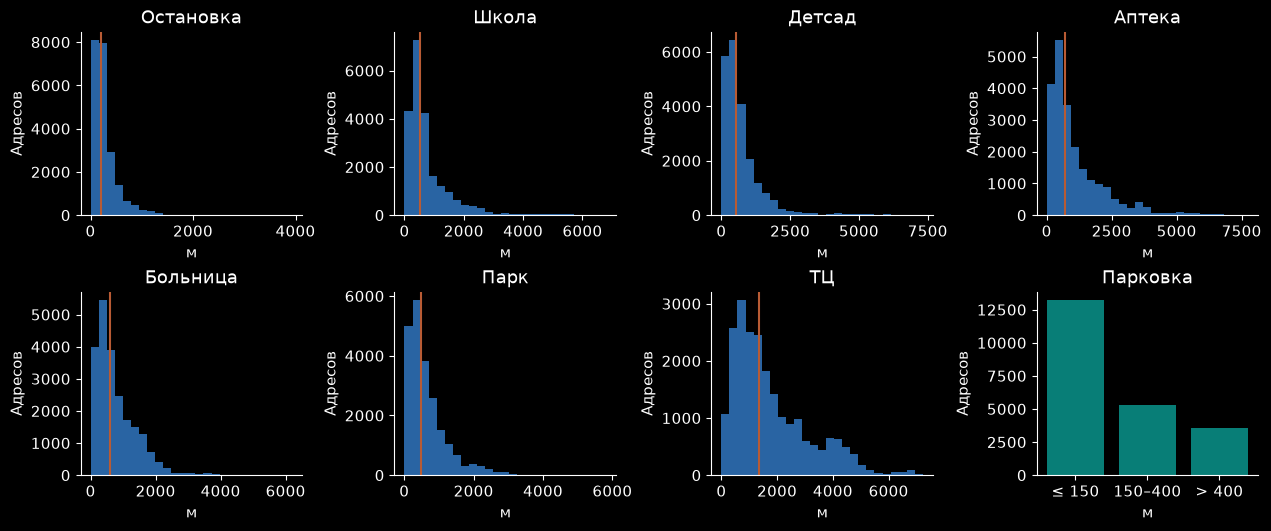

Медиана расстояния до остановки **203 м**, до ТЦ **1361 м**. Ближайшая парковка в пределах 150 м есть на карте для **59.8%** адресов.

In [21]:
fig, axes = plt.subplots(2, 4, figsize=(12.6, 5.2), layout='constrained')
for ax, feature, title in zip(axes.flat, DISTANCES, places):
    houses[feature].hist(ax=ax, bins=25, color=blue, grid=False)
    ax.axvline(houses[feature].median(), color=terracotta, lw=1.5)
    ax.set(title=title, xlabel='м', ylabel='Адресов')
park_count = houses['parking'].value_counts().reindex(PARKING)
axes.flat[7].bar(['≤ 150', '150–400', '> 400'], park_count, color=teal)
axes.flat[7].set(title='Парковка', xlabel='м', ylabel='Адресов')
plt.show()

medians = houses[DISTANCES].median()
display(Markdown(
    f'Медиана расстояния до остановки **{medians["stop_m"]:.0f} м**, '
    f'до ТЦ **{medians["mall_m"]:.0f} м**. Ближайшая парковка в пределах 150 м '
    f'есть на карте для **{park_count.iloc[0] / len(houses):.1%}** адресов.'
))

### Распределения · желаемые расстояния

Для каждой характеристики анкеты заданы три варианта, полученные из квартилей каталога.
Единица наблюдения — анкета.

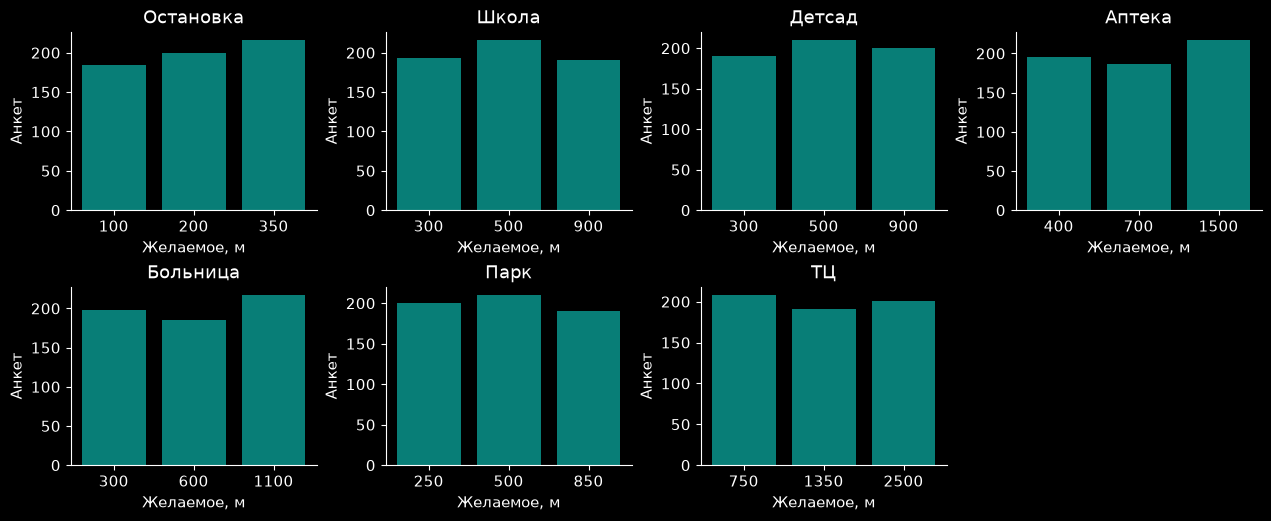

Медианный порог в учебных анкетах составляет **200 м** для остановки и **1350 м** для ТЦ.

In [22]:
fig, axes = plt.subplots(2, 4, figsize=(12.6, 5.1), layout='constrained')
for ax, feature, title in zip(axes.flat, LIMITS, places):
    counts = surveys[feature].value_counts().sort_index()
    ax.bar(counts.index.astype(str), counts, color=teal)
    ax.set(title=title, xlabel='Желаемое, м', ylabel='Анкет')
axes.flat[7].set_visible(False)
plt.show()

display(Markdown(
    f'Медианный порог в учебных анкетах составляет **{surveys["want_stop_m"].median():.0f} м** '
    f'для остановки и **{surveys["want_mall_m"].median():.0f} м** для ТЦ.'
))

### Распределения · важность критериев

0 означает отсутствие пожелания. 3 означает высокий приоритет.

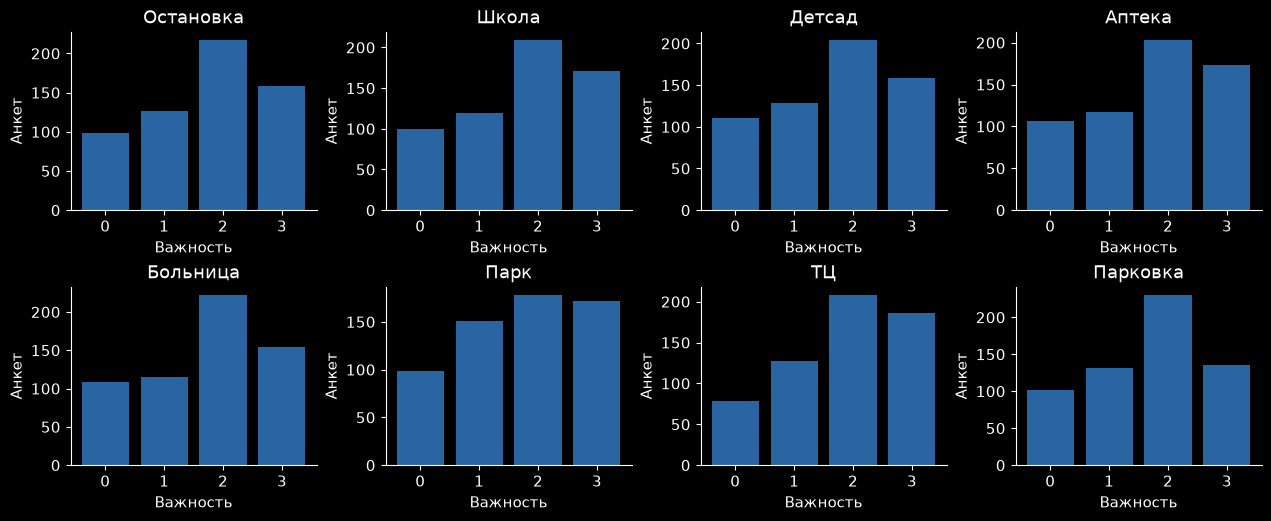

Приоритет 2 или 3 указан у **63.3%** анкет для школы и у **61.0%** для парковки.

In [23]:
fig, axes = plt.subplots(2, 4, figsize=(12.6, 5.1), layout='constrained')
for ax, feature, title in zip(axes.flat, PRIORITIES, places + ['Парковка']):
    counts = surveys[feature].value_counts().reindex(range(4), fill_value=0)
    ax.bar(counts.index, counts, color=blue)
    ax.set(title=title, xlabel='Важность', ylabel='Анкет', xticks=range(4))
plt.show()

high = surveys[PRIORITIES].ge(2).mean()
display(Markdown(
    f'Приоритет 2 или 3 указан у **{high["priority_school"]:.1%}** анкет для школы '
    f'и у **{high["priority_parking"]:.1%}** для парковки.'
))

### Краткие выводы по 23 распределениям

In [24]:
distribution_notes = {}
for field in DISTANCES:
    values = houses[field]
    distribution_notes[field] = (
        f'Медиана {values.median():.0f} м, у 90% адресов до {values.quantile(.9):.0f} м, '
        f'максимум {values.max():.0f} м.'
    )
distribution_notes['parking'] = (
    f'Чаще всего «{park_count.idxmax()}», доля {park_count.max() / len(houses):.1%}.'
)
for field in LIMITS:
    counts = surveys[field].value_counts()
    distribution_notes[field] = (
        f'Уровни {counts.size}, самый частый порог {counts.idxmax()} м '
        f'({counts.max() / len(surveys):.1%} анкет).'
    )
for field in PRIORITIES:
    values = surveys[field]
    distribution_notes[field] = (
        f'Уровень {values.mode().iloc[0]} встречается чаще всего. Важность 2–3 у {values.ge(2).mean():.1%} анкет.'
    )
display(pd.Series(distribution_notes, name='Наблюдение').rename(index=short).to_frame())

,Наблюдение
Остановка дома,"Медиана 203 м, у 90% адресов до 558 м, максиму..."
Школа дома,"Медиана 517 м, у 90% адресов до 1715 м, максим..."
Детсад дома,"Медиана 522 м, у 90% адресов до 1548 м, максим..."
Аптека дома,"Медиана 722 м, у 90% адресов до 2526 м, максим..."
Больница дома,"Медиана 588 м, у 90% адресов до 1636 м, максим..."
Парк дома,"Медиана 479 м, у 90% адресов до 1400 м, максим..."
ТЦ дома,"Медиана 1361 м, у 90% адресов до 3986 м, макси..."
Парковка,"Чаще всего «До 150 м», доля 59.8%."
Остановка в анкете,"Уровни 3, самый частый порог 350 м (36.0% анкет)."
Школа в анкете,"Уровни 3, самый частый порог 500 м (36.0% анкет)."


### Корреляции расстояний по каталогу

Коэффициент Спирмена посчитан по семи расстояниям до объектов. Каждый адрес учитывается один раз.

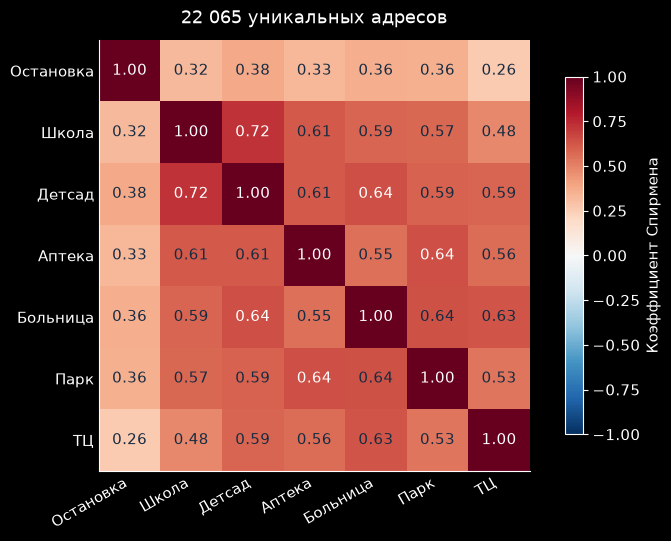

**Полная матрица для 14 400 пар «анкета × дом».** Пороги и важность задаются до выбора адресов. Поэтому связь этих полей с фактическими расстояниями слабая (максимум |ρ| = 0.045). Связь с откликом проверяем ниже по долям «да» при выполнении пожеланий.

,Остановка дома,Школа дома,Детсад дома,Аптека дома,Больница дома,Парк дома,ТЦ дома,Остановка в анкете,Школа в анкете,Детсад в анкете,...,Парк в анкете,ТЦ в анкете,Остановка: важность,Школа: важность,Детсад: важность,Аптека: важность,Больница: важность,Парк: важность,ТЦ: важность,Парковка: важность
Остановка дома,1.00,0.32,0.35,0.31,0.34,0.31,0.24,0.00,0.01,0.00,...,0.00,0.01,0.00,0.00,0.01,0.01,0.00,0.01,-0.02,0.01
Школа дома,0.32,1.00,0.73,0.59,0.59,0.54,0.48,0.01,0.02,0.00,...,-0.01,-0.00,0.01,-0.00,0.03,-0.01,0.02,0.01,0.01,0.00
Детсад дома,0.35,0.73,1.00,0.61,0.64,0.56,0.59,0.01,0.04,0.01,...,0.00,-0.01,0.00,-0.00,0.03,-0.01,0.01,0.01,-0.01,-0.01
Аптека дома,0.31,0.59,0.61,1.00,0.53,0.58,0.57,0.01,0.04,-0.01,...,0.00,0.01,-0.01,-0.01,0.00,0.00,0.02,0.01,0.00,-0.00
Больница дома,0.34,0.59,0.64,0.53,1.00,0.61,0.59,-0.01,0.04,0.02,...,-0.00,-0.02,0.01,-0.01,0.02,-0.02,0.01,0.01,0.00,-0.01
Парк дома,0.31,0.54,0.56,0.58,0.61,1.00,0.49,-0.01,0.04,0.01,...,-0.00,0.00,-0.01,-0.01,0.01,0.01,0.02,0.03,0.00,-0.00
ТЦ дома,0.24,0.48,0.59,0.57,0.59,0.49,1.00,0.01,0.05,0.00,...,-0.02,0.01,0.01,-0.03,0.03,-0.01,0.03,0.02,-0.00,-0.01
Остановка в анкете,0.00,0.01,0.01,0.01,-0.01,-0.01,0.01,1.00,0.03,-0.03,...,-0.02,0.01,0.01,0.02,0.04,-0.07,-0.04,0.02,0.04,-0.04
Школа в анкете,0.01,0.02,0.04,0.04,0.04,0.04,0.05,0.03,1.00,0.02,...,-0.05,-0.07,-0.02,0.03,-0.05,-0.06,-0.02,-0.04,-0.01,-0.04
Детсад в анкете,0.00,0.00,0.01,-0.01,0.02,0.01,0.00,-0.03,0.02,1.00,...,0.01,-0.02,0.03,0.04,0.01,0.00,0.02,-0.11,0.00,-0.11


In [25]:
catalog_rho = houses[DISTANCES].corr(method='spearman')
fig, ax = plt.subplots(figsize=(8.4, 5.3), layout='constrained')
image = ax.imshow(catalog_rho, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(len(places)), places, rotation=30, ha='right')
ax.set_yticks(range(len(places)), places)
ax.set_title(f'{len(houses):,} уникальных адресов'.replace(',', ' '), pad=12)
ax.tick_params(length=0)

for i, row in enumerate(catalog_rho.to_numpy()):
    for j, value in enumerate(row):
        color = 'white' if abs(value) >= .64 else ink
        ax.text(j, i, f'{value:.2f}', ha='center', va='center', color=color)

fig.colorbar(image, ax=ax, shrink=.83, label='Коэффициент Спирмена')
plt.show()

numeric = DISTANCES + LIMITS + PRIORITIES
pair_rho = eda[numeric].corr(method='spearman')
cross = pair_rho.loc[DISTANCES, LIMITS + PRIORITIES].abs().max().max()
display(Markdown(
    f'**Полная матрица для {len(eda):,} пар «анкета × дом».** '.replace(',', ' ')
    + 'Пороги и важность задаются до выбора адресов. '
    f'Поэтому связь этих полей с фактическими расстояниями слабая (максимум |ρ| = {cross:.3f}). '
    'Связь с откликом проверяем ниже по долям «да» при выполнении пожеланий.'
))
display(pair_rho.rename(index=short, columns=short).round(2))

### Корреляции · сильные связи расстояний

Две пары с наибольшим абсолютным коэффициентом в каталоге. Цвет показывает плотность адресов.

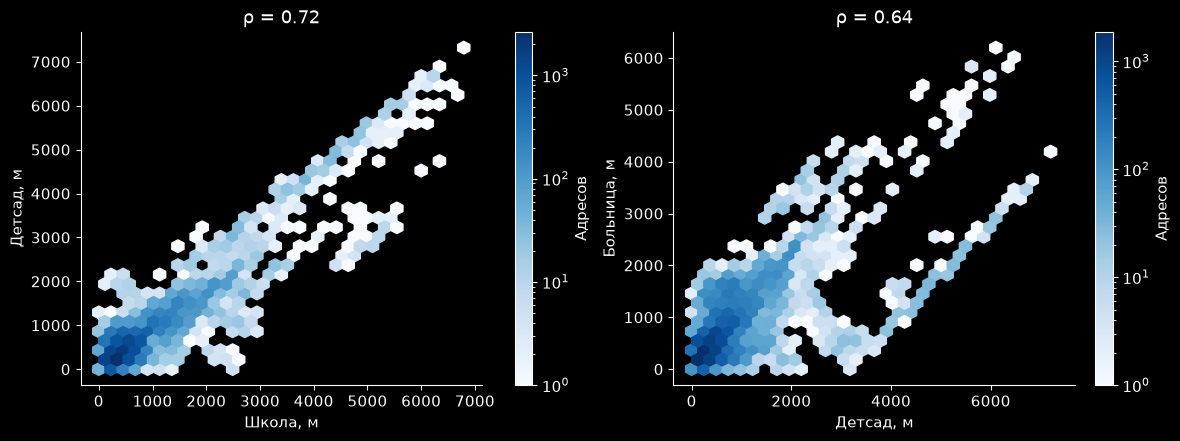

У школы и детсада **ρ = 0.72**. У многих адресов близость одного объекта сопровождается близостью второго.

In [26]:
catalog_rho = houses[DISTANCES].corr(method='spearman')
upper = np.triu(np.ones(catalog_rho.shape, dtype=bool), k=1)
relations = catalog_rho.where(upper).stack()
strongest = relations.reindex(relations.abs().nlargest(2).index)
names = dict(zip(DISTANCES, places))
fig, axes = plt.subplots(1, 2, figsize=(11.7, 4.3), layout='constrained')
for ax, ((x, y), value) in zip(axes, strongest.items()):
    image = ax.hexbin(houses[x], houses[y], gridsize=30, mincnt=1, bins='log', cmap='Blues')
    ax.set(xlabel=f'{names[x]}, м', ylabel=f'{names[y]}, м', title=f'ρ = {value:.2f}')
    fig.colorbar(image, ax=ax, label='Адресов')
plt.show()

display(Markdown(
    f'У школы и детсада **ρ = {catalog_rho.loc["school_m", "kindergarten_m"]:.2f}**. '
    'У многих адресов близость одного объекта сопровождается близостью второго.'
))

### Статистика · расстояния до объектов

Ящик показывает средние 50% значений, линия внутри него — медиану.
Точки за усами отмечены правилом 1,5 IQR.

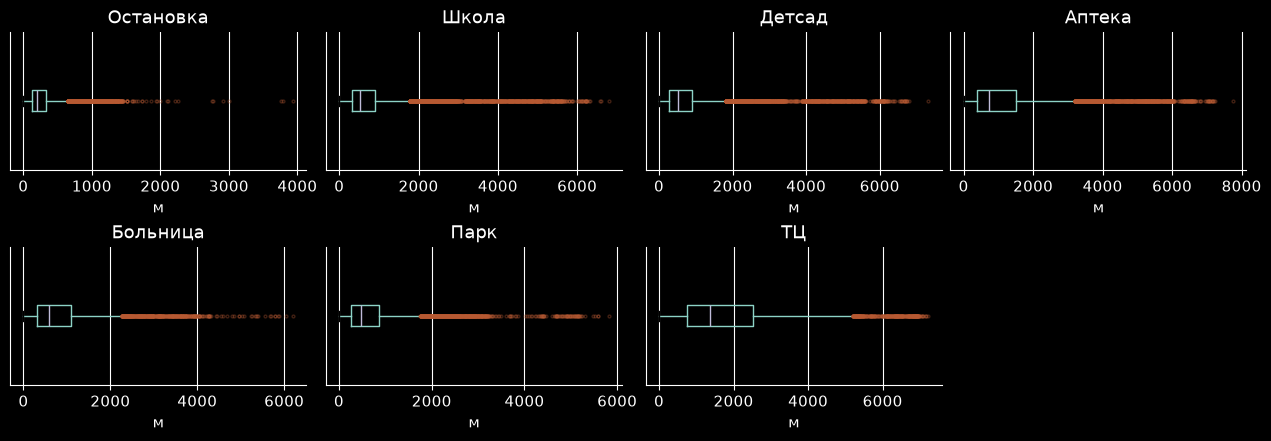

In [27]:
fig, axes = plt.subplots(2, 4, figsize=(12.6, 4.3), layout='constrained')
for ax, feature, title in zip(axes.flat, DISTANCES, places):
    houses.boxplot(column=feature, ax=ax, tick_labels=[''], vert=False,
                   flierprops={'markersize': 2, 'markeredgecolor': terracotta, 'alpha': .35})
    ax.set(title=title, xlabel='м')
    ax.set_yticks([])
axes.flat[7].set_visible(False)
plt.show()

### Статистика · параметры анкет

Boxplot обобщает ответы. Дискретные уровни важности и разрешённые пороги проверяются по их шкале.

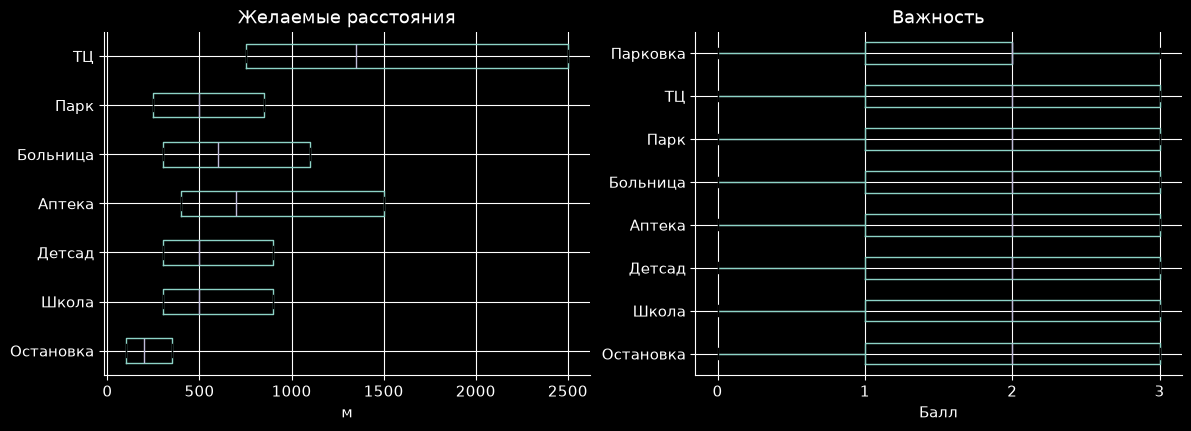

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(11.8, 4.2), layout='constrained')
surveys[LIMITS].rename(columns=dict(zip(LIMITS, places))).boxplot(ax=axes[0], vert=False)
surveys[PRIORITIES].rename(columns=dict(zip(PRIORITIES, places + ['Парковка']))).boxplot(
    ax=axes[1], vert=False
)
axes[0].set(title='Желаемые расстояния', xlabel='м')
axes[1].set(title='Важность', xlabel='Балл', xticks=range(4))
plt.show()

### Статистика · качество всех полей

Для признаков дома количество значений считается по каталогу, для параметров анкеты — по анкетам.
Допустимые дальние расстояния описывают адреса с низкой доступностью.

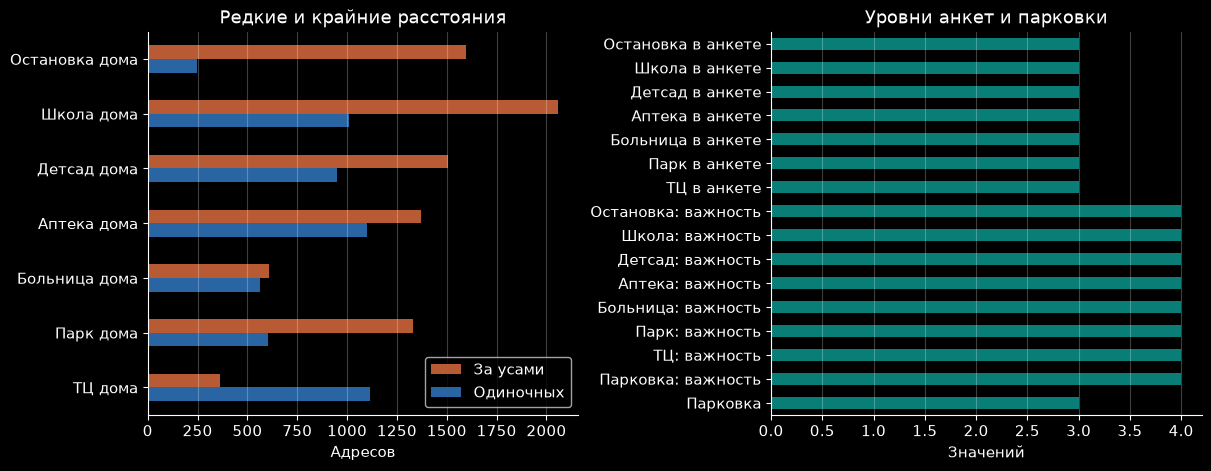

В 23 признаках **0 пропусков** и **0 значений вне допустимой шкалы**. У поля «Остановка» 1596 адресов за усами.

In [29]:
def quality_table(frame, numeric_fields, invalid):
    table = pd.DataFrame({
        'Пропусков': frame.isnull().sum(),
        'Различных': frame.nunique(),
        'Одиночных': [frame[col].value_counts().eq(1).sum() for col in frame],
        'Вне шкалы': invalid.sum().reindex(frame.columns, fill_value=0),
        'За усами': 0,
    })
    values = frame[numeric_fields]
    q1, q3 = values.quantile([.25, .75]).to_numpy()
    iqr = q3 - q1
    table.loc[numeric_fields, 'За усами'] = (
        values.lt(q1 - 1.5 * iqr) | values.gt(q3 + 1.5 * iqr)
    ).sum()
    return table


bad_house = houses[DISTANCES].lt(0) | ~np.isfinite(houses[DISTANCES])
bad_house['parking'] = ~houses['parking'].isin(PARKING)
bad_survey = surveys[LIMITS].le(0).join(~surveys[PRIORITIES].isin([0, 1, 2, 3]))
quality = pd.concat([
    quality_table(houses[DISTANCES + ['parking']], DISTANCES, bad_house),
    quality_table(surveys[LIMITS + PRIORITIES], LIMITS + PRIORITIES, bad_survey),
])
quality.loc[PRIORITIES, 'За усами'] = 0
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), layout='constrained')
quality.loc[DISTANCES, ['За усами', 'Одиночных']].rename(index=short).plot.barh(
    ax=axes[0], color=[terracotta, blue], xlabel='Адресов', title='Редкие и крайние расстояния')
quality['Различных'].loc[LIMITS + PRIORITIES + ['parking']].rename(index=short).plot.barh(
    ax=axes[1], color=teal, xlabel='Значений', title='Уровни анкет и парковки')
for ax in axes:
    ax.invert_yaxis()
    ax.grid(axis='x', alpha=.25)
plt.show()
display(Markdown(
    f'В 23 признаках **{quality["Пропусков"].sum()} пропусков** и '
    f'**{quality["Вне шкалы"].sum()} значений вне допустимой шкалы**. '
    f'У поля «Остановка» {quality.loc["stop_m", "За усами"]} адресов за усами.'
))

In [30]:
display(quality.rename(index=short))
display(houses[DISTANCES].eq(0).sum().rename('Нулевых расстояний').to_frame().rename(index=short))

,Пропусков,Различных,Одиночных,Вне шкалы,За усами
Остановка дома,0,1288,248,0,1596
Школа дома,0,3089,1009,0,2057
Детсад дома,0,2888,951,0,1505
Аптека дома,0,3929,1098,0,1370
Больница дома,0,2681,564,0,607
Парк дома,0,2529,605,0,1330
ТЦ дома,0,4956,1117,0,365
Парковка,0,3,0,0,0
Остановка в анкете,0,3,0,0,0
Школа в анкете,0,3,0,0,0


,Нулевых расстояний
Остановка дома,0
Школа дома,1
Детсад дома,0
Аптека дома,2
Больница дома,15
Парк дома,0
ТЦ дома,12


### Кодирование категорий и повторная проверка

Для парковки создаём отдельный бинарный столбец на категорию. Числа пока остаются в исходных шкалах.

<class 'pandas.DataFrame'>
Index: 14400 entries, 0 to 17999
Data columns (total 25 columns):
 #   Column                 Non-Null Count  Dtype
---  ------                 --------------  -----
 0   stop_m                 14400 non-null  int64
 1   school_m               14400 non-null  int64
 2   kindergarten_m         14400 non-null  int64
 3   pharmacy_m             14400 non-null  int64
 4   hospital_m             14400 non-null  int64
 5   park_m                 14400 non-null  int64
 6   mall_m                 14400 non-null  int64
 7   want_stop_m            14400 non-null  int64
 8   want_school_m          14400 non-null  int64
 9   want_kindergarten_m    14400 non-null  int64
 10  want_pharmacy_m        14400 non-null  int64
 11  want_hospital_m        14400 non-null  int64
 12  want_park_m            14400 non-null  int64
 13  want_mall_m            14400 non-null  int64
 14  priority_stop          14400 non-null  int64
 15  priority_school        14400 non-null  int64
 16  pr

,stop_m,school_m,kindergarten_m,pharmacy_m,hospital_m,park_m,mall_m,want_stop_m,want_school_m,want_kindergarten_m,...,priority_school,priority_kindergarten,priority_pharmacy,priority_hospital,priority_park,priority_mall,priority_parking,parking_150–400 м,parking_Дальше 400 м,parking_До 150 м
0,1221,1789,1532,3587,1704,2096,3899,350,300,500,...,1,3,2,0,3,3,2,0,1,0
1,201,519,317,2180,282,903,2728,350,300,500,...,1,3,2,0,3,3,2,1,0,0
2,975,2417,2140,3994,2355,2407,4423,350,300,500,...,1,3,2,0,3,3,2,0,1,0


,count,mean,std,min,25%,50%,75%,max
stop_m,14400.0,263.50,224.19,6.0,122.0,199.0,325.0,2995.0
school_m,14400.0,742.16,775.46,8.0,296.0,496.0,848.0,6575.0
kindergarten_m,14400.0,704.96,770.89,3.0,261.0,481.0,860.0,6691.0
pharmacy_m,14400.0,1074.54,1042.67,2.0,374.0,706.0,1412.0,7142.0
hospital_m,14400.0,719.09,614.61,0.0,294.0,532.0,969.0,6036.0
park_m,14400.0,614.90,560.84,6.0,247.0,450.5,791.0,5299.0
mall_m,14400.0,1673.44,1288.61,0.0,705.0,1288.0,2278.5,7227.0
want_stop_m,14400.0,224.69,103.69,100.0,100.0,200.0,350.0,350.0
want_school_m,14400.0,562.50,242.07,300.0,300.0,500.0,900.0,900.0
want_kindergarten_m,14400.0,578.33,247.39,300.0,300.0,500.0,900.0,900.0


,Пропусков,Различных,Одиночных,Вне шкалы,За усами
Остановка дома,0,1039,179,0,940
Школа дома,0,2286,634,0,1276
Детсад дома,0,2184,550,0,890
Аптека дома,0,3037,816,0,887
Больница дома,0,2204,408,0,563
Парк дома,0,1988,431,0,805
ТЦ дома,0,3856,1040,0,466
Остановка в анкете,0,3,0,0,0
Школа в анкете,0,3,0,0,0
Детсад в анкете,0,3,0,0,0


Совпавшие строки признаков после кодирования: 0


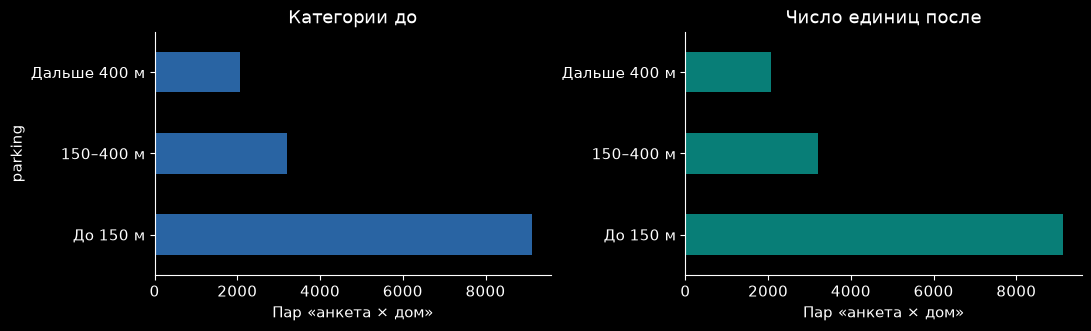

In [31]:
encoded = pd.get_dummies(eda[FEATURES], columns=['parking'], dtype='int8')
indicator_fields = encoded.columns.difference(numeric).tolist()
assert encoded[indicator_fields].sum(axis=1).eq(1).all()
encoded.info()
display(encoded.head(3))
display(encoded.describe().T.round(2))

invalid_encoded = encoded[DISTANCES].lt(0).join(encoded[LIMITS].le(0))
invalid_encoded = invalid_encoded.join(~encoded[PRIORITIES + indicator_fields].isin([0, 1, 2, 3]))
invalid_encoded[indicator_fields] = ~encoded[indicator_fields].isin([0, 1])
encoded_quality = quality_table(encoded, DISTANCES + LIMITS, invalid_encoded)
display(encoded_quality.rename(index=short))
print('Совпавшие строки признаков после кодирования:', encoded.duplicated().sum())

fig, axes = plt.subplots(1, 2, figsize=(10.8, 3.2), layout='constrained')
eda['parking'].value_counts().reindex(PARKING).plot.barh(ax=axes[0], color=blue, title='Категории до')
encoded[indicator_fields].sum().rename(lambda name: name.removeprefix('parking_')).reindex(PARKING).plot.barh(
    ax=axes[1], color=teal, title='Число единиц после'
)
for ax in axes:
    ax.set_xlabel('Пар «анкета × дом»')
plt.show()

Сумма единиц в новых столбцах воспроизводит частоты категорий. Для бинарных столбцов проверяется диапазон 0–1.
Признаки времени в проекте отсутствуют, а расстояния проверяются по неотрицательности.

### Наблюдение 1 · выполнение порога и ответ анкеты

Для каждого объекта смотрим пары, где его важность равна 2 или 3. Сравниваем долю учебных ответов «да»
при соблюдении и превышении желаемого расстояния.

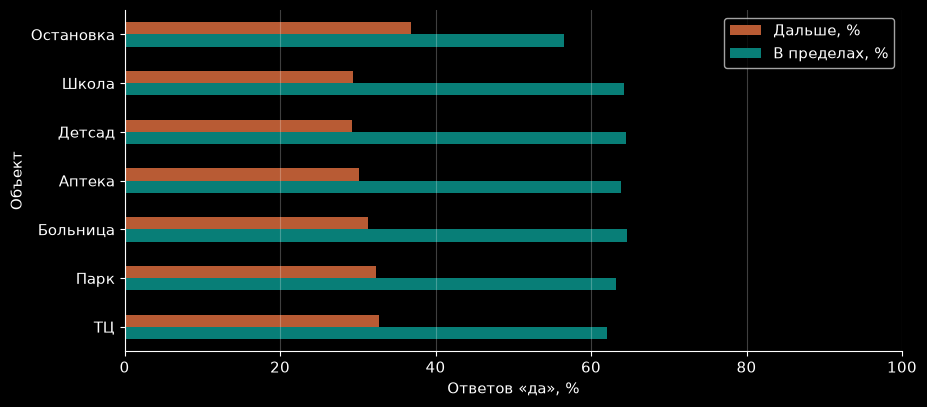

Наибольшая разница в этом сравнении у критерия **«Детсад»**. При соблюдении порога **64.5%** ответов «да» (n=4522) против **29.3%** (n=3848). Разница **35.2 п. п.**

In [32]:
def summarize_answers(frame, columns):
    summary = frame.groupby(columns, observed=True)[TARGET].agg(n='size', yes='sum')
    return summary.assign(rate=100 * summary['yes'] / summary['n'])


rows = []
for distance, limit, priority, name in zip(DISTANCES, LIMITS, PRIORITIES, places):
    group = eda.loc[eda[priority].ge(2)].copy()
    group['within_limit'] = group[distance].le(group[limit])
    summary = summarize_answers(group, 'within_limit').reindex([False, True])
    rows.append({
        'Объект': name, 'Дальше, n': summary.loc[False, 'n'], 'В пределах, n': summary.loc[True, 'n'],
        'Дальше, %': summary.loc[False, 'rate'], 'В пределах, %': summary.loc[True, 'rate'],
    })
threshold_stats = pd.DataFrame(rows).set_index('Объект')
threshold_stats['Разница, п. п.'] = threshold_stats['В пределах, %'] - threshold_stats['Дальше, %']

ax = threshold_stats[['Дальше, %', 'В пределах, %']].plot.barh(
    figsize=(9.4, 4.2), color=[terracotta, teal], xlim=(0, 100), xlabel='Ответов «да», %',
)
ax.invert_yaxis()
ax.grid(axis='x', alpha=.25)
plt.tight_layout()
plt.show()

strong = threshold_stats['Разница, п. п.'].idxmax()
row = threshold_stats.loc[strong]
display(Markdown(
    f'Наибольшая разница в этом сравнении у критерия **«{strong}»**. При соблюдении порога '
    f'**{row["В пределах, %"]:.1f}%** ответов «да» (n={row["В пределах, n"]:.0f}) '
    f'против **{row["Дальше, %"]:.1f}%** (n={row["Дальше, n"]:.0f}). '
    f'Разница **{row["Разница, п. п."]:.1f} п. п.**'
))

In [33]:
display(threshold_stats.round(1))

,"Дальше, n","В пределах, n","Дальше, %","В пределах, %","Разница, п. п."
Объект,,,,,
Остановка,4199,4381,36.8,56.6,19.7
Школа,4417,4613,29.4,64.3,34.9
Детсад,3848,4522,29.3,64.5,35.2
Аптека,4303,4637,30.1,63.9,33.8
Больница,4219,4721,31.3,64.7,33.4
Парк,4180,4340,32.3,63.2,30.9
ТЦ,4495,4865,32.7,62.1,29.4


### Наблюдение 2 · сочетания условий

Сначала сравниваем школу и детсад среди анкет, где важны оба объекта.
Затем сравниваем категории парковки отдельно при низком и высоком приоритете.

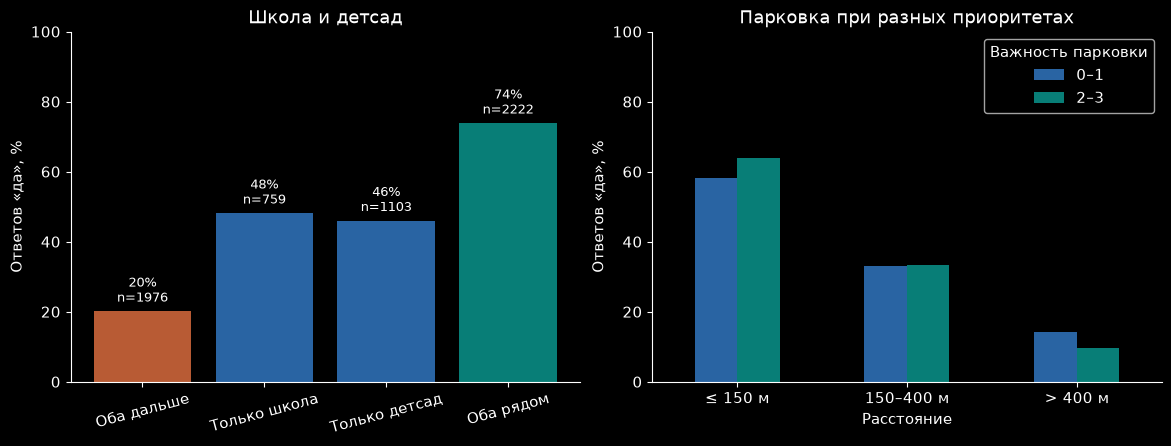

Школа и детсад рядом одновременно дают разницу **53.7 п. п.** относительно группы «оба дальше». Разница между ближайшей и дальней парковкой составляет **54.4 п. п.** при важности 2–3 и **43.9 п. п.** при важности 0–1.

In [34]:
education = eda.loc[eda['priority_school'].ge(2) & eda['priority_kindergarten'].ge(2)].copy()
education['school_near'] = education['school_m'].le(education['want_school_m'])
education['kindergarten_near'] = education['kindergarten_m'].le(education['want_kindergarten_m'])
education_order = [(False, False), (True, False), (False, True), (True, True)]
education_stats = summarize_answers(education, ['school_near', 'kindergarten_near']).reindex(education_order)
education_stats.index = ['Оба дальше', 'Только школа', 'Только детсад', 'Оба рядом']

parking_groups = eda.assign(parking_priority=np.where(eda['priority_parking'].ge(2), '2–3', '0–1'))
parking_stats = summarize_answers(parking_groups, ['parking_priority', 'parking'])
parking_rates = parking_stats['rate'].unstack(0).reindex(PARKING)

fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.35), layout='constrained')
bars = axes[0].bar(education_stats.index, education_stats['rate'], color=[terracotta, blue, blue, teal])
axes[0].bar_label(bars, labels=[f'{rate:.0f}%\nn={n}' for rate, n in
                              zip(education_stats['rate'], education_stats['n'])], padding=4, fontsize=9)
axes[0].tick_params(axis='x', labelrotation=15)
axes[0].set(title='Школа и детсад', ylim=(0, 100), ylabel='Ответов «да», %')
parking_rates.rename(index=dict(zip(PARKING, ['≤ 150 м', '150–400 м', '> 400 м']))).plot.bar(
    ax=axes[1], color=[blue, teal], rot=0, xlabel='Расстояние', ylabel='Ответов «да», %',
    title='Парковка при разных приоритетах', ylim=(0, 100),
)
axes[1].legend(title='Важность парковки')
plt.show()

education_gap = education_stats.loc['Оба рядом', 'rate'] - education_stats.loc['Оба дальше', 'rate']
parking_gaps = parking_rates.iloc[0] - parking_rates.iloc[-1]
display(Markdown(
    f'Школа и детсад рядом одновременно дают разницу **{education_gap:.1f} п. п.** '
    f'относительно группы «оба дальше». Разница между ближайшей и дальней парковкой '
    f'составляет **{parking_gaps["2–3"]:.1f} п. п.** при важности 2–3 '
    f'и **{parking_gaps["0–1"]:.1f} п. п.** при важности 0–1.'
))

In [35]:
display(education_stats.round(1))
display(parking_stats.round(1))

,n,yes,rate
Оба дальше,1976,397,20.1
Только школа,759,365,48.1
Только детсад,1103,507,46.0
Оба рядом,2222,1640,73.8


n   yes  rate
parking_priority parking                       
0–1              150–400 м     1335   441  33.0
                 Дальше 400 м   779   111  14.2
                 До 150 м      3556  2067  58.1
2–3              150–400 м     1877   628  33.5
                 Дальше 400 м  1286   124   9.6
                 До 150 м      5567  3563  64.0

Числа в группах относятся к парам «анкета × дом». Одна анкета оценивает несколько адресов.
Эти доли описывают ответы учебных анкет. На совместную близость школы и детсада влияет и расположение
инфраструктуры, и правило генерации учебного выбора.